# IS 4487 Assignment 5: Exploratory Data Analysis (EDA) with Stakeholder Framing

In this assignment, you will:
- Load and explore a hotel bookings dataset
- Identify stakeholder needs and frame your analysis around business goals
- Practice data summarization and visualization
- Draw insights that could lead to actionable business recommendations

## Why This Matters

These skills are essential for business majors and minors working in areas like marketing, operations, finance, or consulting. Understanding how to explore and communicate data-driven insights helps you make better decisions and contribute to real-world business outcomes.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_05_eda.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.


## 1. Setup and Data Loading

Instructions:
- Import `pandas`, `seaborn`, and `matplotlib.pyplot`.
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows to confirm it loaded correctly.


In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv')

# Display the first few rows
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Stakeholder and Business Context

### Business framing:  

Every analysis should serve a decision-maker. Before you explore the data, identify who cares about hotel booking behavior and what they might want to know. Your analysis should be framed around those needs.

### Reflection:
1. Who are the key stakeholders for this dataset?
2. What goals might each stakeholder have?
3. What is a clear, specific business problem statement that this data can help answer?





### ✍️ Your Response: 🔧
1. Key stakeholders are those who are investing into these hotels and giving money to fund the buildings.

2. To understand the demographic, when people are checking in, how many rooms are being used. This way they can curate the perfect hotel stay for their demographic.

3. Understanding what is making guests cancel their reservations and how the business can fix that problem.




## 3. Explore Data Structure and Quality

### Business framing:  

Before diving into analysis, analysts need to understand the shape and health of the data. Bad data leads to bad decisions.

### Do the following:
- Perform the following 3 checks to see the data quality:
  - Summary the data (e.g., `.info()`, `.describe()`)
  - Find the number of Null values
  - Find the number of duplicate row checks


In [6]:
print("DataFrame Info:")
df.info()

print("\nDataFrame Description:")
df.describe()

print("\nNumber of Null Values per Column:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9404 entries, 0 to 9403
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           9404 non-null   object 
 1   is_canceled                     9404 non-null   int64  
 2   lead_time                       9404 non-null   int64  
 3   arrival_date_year               9404 non-null   int64  
 4   arrival_date_month              9404 non-null   object 
 5   arrival_date_week_number        9404 non-null   int64  
 6   arrival_date_day_of_month       9404 non-null   int64  
 7   stays_in_weekend_nights         9404 non-null   int64  
 8   stays_in_week_nights            9404 non-null   int64  
 9   adults                          9404 non-null   int64  
 10  children                        9404 non-null   int64  
 11  babies                          9404 non-null   int64  
 12  meal              

### Reflection:
1. Name at least one structure issue you’ve found (e.g., missing values, formatting problems).
2. How can you fix this structural issue?

### ✍️ Your Response: 🔧
1. There are 1674 duplicate rows in the dataset.

2. Going through the data and removing any duplicate rows, clean up the data.



## 4. Univariate Analysis

### Business framing:  

Hotels care about trends like average stay length, customer mix, and pricing. A good EDA starts with understanding single variables and their distribution.

### Do the following:
- Select at least 3 individual variables to explore
- Use plots and summary methods (e.g. info(), describe(), etc)  to describe the distribution (hint: we are only looking at the values of one variable, so think of plots you've used in the past that DON'T compare 2 variables.)
- Focus on what matters from a business standpoint (e.g., pricing, cancellations, guest types)


--- Analysis of 'is_canceled' ---
Value Counts:
is_canceled
0    7069
1    2335
Name: count, dtype: int64

Percentage of Cancellations:
is_canceled
0    75.17014
1    24.82986
Name: proportion, dtype: float64


/tmp/ipykernel_788/4003346329.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='is_canceled', palette='viridis')


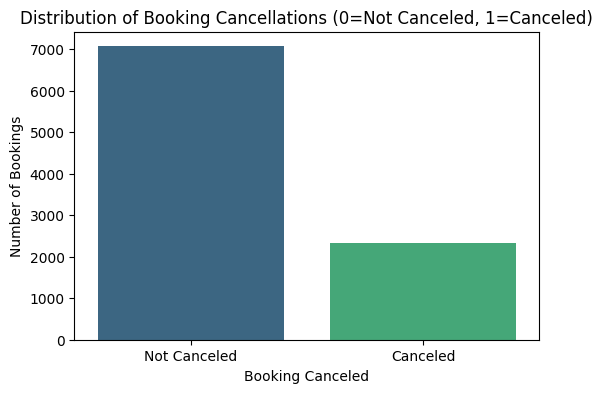


--- Analysis of 'lead_time' ---
Descriptive Statistics:
count    9404.000000
mean       79.326244
std        87.584146
min         0.000000
25%         8.000000
50%        48.000000
75%       118.000000
max       737.000000
Name: lead_time, dtype: float64


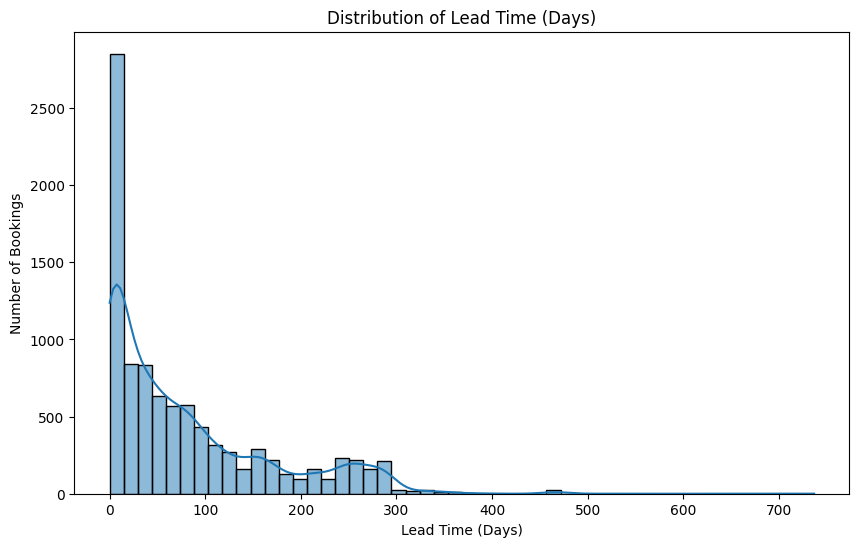


--- Analysis of 'adr' ---
Descriptive Statistics:
count    9404.000000
mean       86.843614
std        53.759940
min        -6.380000
25%        45.000000
50%        71.550000
75%       120.600000
max       508.000000
Name: adr, dtype: float64


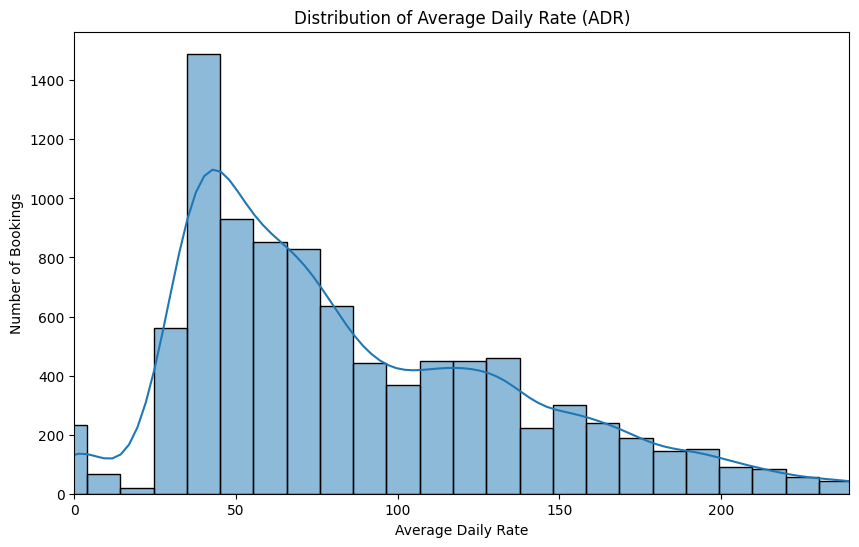

In [7]:
# 1. Analysis of 'is_canceled'
print("\n--- Analysis of 'is_canceled' ---")
print("Value Counts:")
print(df['is_canceled'].value_counts())
print("\nPercentage of Cancellations:")
print(df['is_canceled'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_canceled', palette='viridis')
plt.title('Distribution of Booking Cancellations (0=Not Canceled, 1=Canceled)')
plt.xlabel('Booking Canceled')
plt.ylabel('Number of Bookings')
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.show()

# 2. Analysis of 'lead_time'
print("\n--- Analysis of 'lead_time' ---")
print("Descriptive Statistics:")
print(df['lead_time'].describe())

plt.figure(figsize=(10, 6))
sns.histplot(df['lead_time'], bins=50, kde=True)
plt.title('Distribution of Lead Time (Days)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')
plt.show()

# 3. Analysis of 'adr' (Average Daily Rate)
print("\n--- Analysis of 'adr' ---")
print("Descriptive Statistics:")
print(df['adr'].describe())

plt.figure(figsize=(10, 6))
sns.histplot(df['adr'], bins=50, kde=True)
plt.title('Distribution of Average Daily Rate (ADR)')
plt.xlabel('Average Daily Rate')
plt.ylabel('Number of Bookings')
plt.xlim(0, df['adr'].quantile(0.99)) # Limit x-axis to 99th percentile to better visualize main distribution
plt.show()

### Reflection:
1. Variable 1 – What did you explore and what did you find?
2. Variable 2 – What did you explore and what did you find?
3. Variable 3 – What did you explore and what did you find?

### ✍️ Your Response: 🔧
- **Variable 1 – Summary and insights:**  The first variable is is_canceled. There is a significant amount of bookings not cancelled in comparison to those that are cancelled.
- **Variable 2 – Summary and insights:**  The second variable is lead_time, more bookings are booked with barely any lead time before the reservation.
- **Variable 3 – Summary and insights:**  The third variable is adr, the chart shows that less than 50 rooms/day is the highest average.


## 5. Bivariate Analysis

### Business framing:  

Stakeholders often ask: “What drives cancellations?” or “Do longer stays mean higher revenue?” Bivariate analysis helps you uncover those kinds of relationships.

### Do the following:
- Choose 2 relevant variable pairs (e.g., `lead_time` vs. `is_canceled`, or `adr` vs. `customer_type`)
- Use scatterplots, grouped bar plots, or boxplots to explore the relationships
- Interpret what these relationships could mean for the hotel business


--- Analysis of 'lead_time' vs. 'is_canceled' ---


/tmp/ipykernel_788/3847911912.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_canceled', y='lead_time', data=df, palette='pastel')


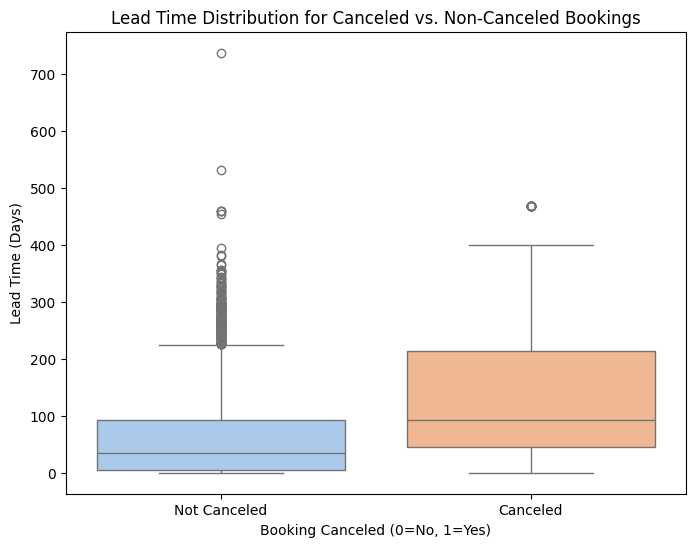

Insight: Longer lead times appear to be associated with a higher likelihood of cancellation. This could indicate that guests booking far in advance have less firm plans or are more likely to find alternative accommodations.

--- Analysis of 'hotel' vs. 'adr' ---


/tmp/ipykernel_788/3847911912.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='hotel', y='adr', data=df, palette='viridis')


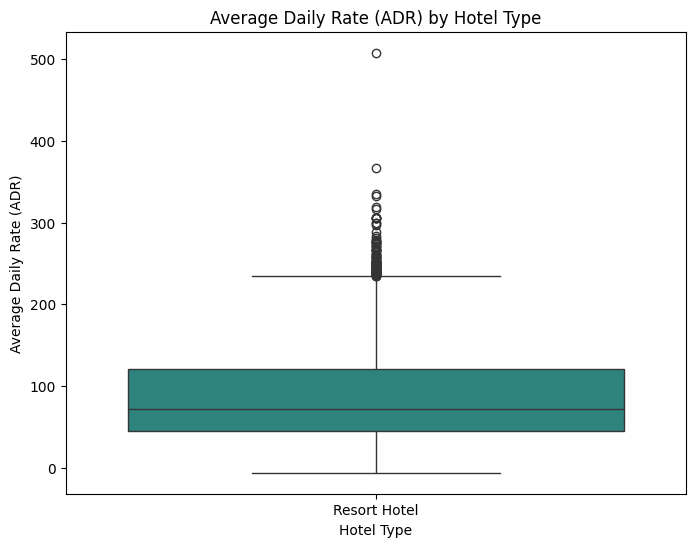

Insight: The Average Daily Rate (ADR) tends to be higher for Resort Hotels compared to City Hotels. This suggests different pricing strategies or customer segments for each hotel type.


In [8]:
# Pair 1: Relationship between Lead Time and Cancellation Status
print("\n--- Analysis of 'lead_time' vs. 'is_canceled' ---")
plt.figure(figsize=(8, 6))
sns.boxplot(x='is_canceled', y='lead_time', data=df, palette='pastel')
plt.title('Lead Time Distribution for Canceled vs. Non-Canceled Bookings')
plt.xlabel('Booking Canceled (0=No, 1=Yes)')
plt.ylabel('Lead Time (Days)')
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.show()
print("Insight: Longer lead times appear to be associated with a higher likelihood of cancellation. This could indicate that guests booking far in advance have less firm plans or are more likely to find alternative accommodations.")

# Pair 2: Relationship between Hotel Type and Average Daily Rate (ADR)
print("\n--- Analysis of 'hotel' vs. 'adr' ---")
plt.figure(figsize=(8, 6))
sns.boxplot(x='hotel', y='adr', data=df, palette='viridis')
plt.title('Average Daily Rate (ADR) by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.show()
print("Insight: The Average Daily Rate (ADR) tends to be higher for Resort Hotels compared to City Hotels. This suggests different pricing strategies or customer segments for each hotel type.")

### Reflection:
1. Relationship 1 – What did you analyze and what insights did you find?
2. Relationship 2 – What did you analyze and what insights did you find?

### ✍️ Your Response: 🔧
- **Relationship 1:**  The distribution for cancelled/noncencelled bookings and lead time show that bookings with more lead time have a higher average of cancelations.
- **Relationship 2:**  The second relationship shows that the average daily rate is higher for resort hotels in comparison to city hotels.


## 6. Problem Complexity and Analytics Framing

### Business framing:  

Let’s say you found a strong trend — maybe high lead times predict cancellations, or certain channels bring repeat guests. What kind of problem is this?

- Choose one insight from your earlier analysis
- Reflect on:
  - What type of complexity this problem represents (e.g., variety, volume, variability)
  - What kind of analytics would help solve or explain it (descriptive, diagnostic, predictive, prescriptive)

### Reflection:
1. What was your selected insight?
2. What kind of complexity does it involve?
3. What type of analytics would help, and why?



### ✍️ Your Response: 🔧
1. The relationship between lead times and cancellatinons. The more lead time between bookings, the higher the liklihood of the reservation being cancelled.
2. It involes understanding how to decrease these cancelations so the company can keep up profits.
3. If customers could put a reason as to why they cancelled the reservation, the business could figure out how to fix any issues.



## 7. Final Takeaways and Recommendations

### Business framing:  

Imagine you’re preparing for a stakeholder meeting. What would you highlight from your findings?

### Reflection:
- 1. What patterns or trends stood out?
- 2. How do they connect to stakeholder goals?
- 3. What recommendation would you make based on this analysis?
- 4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The average daily rate of reservation bookings is a little less than 50 rooms/day.

2. The stakeholders want to increase profit by increasing how many people are booking reservations. It's important to increase this adr to increase profit.

3. I would recommend more advertising towards the target demographic, maybe some loyalty program or deals on bookings.

4. It helps me understand how data analytics can help improve business. Understanding how certain variables have relationships proves that the future of the business can be manipulated.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_05_eda.ipynb"